In [12]:
!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [13]:
!pip install --upgrade kaggle

In [14]:
!kaggle datasets list -s "covid19 image"

ref                                                           title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
sachinkumar413/covid-pneumonia-normal-chest-xray-images       COVID19+PNEUMONIA+NORMAL Chest X-Ray Image Dataset    290862263  2021-01-18 23:08:48.113000           5735         55  0.875            
alsaniipe/chest-x-ray-image                                   Chest X-ray Image(COVID19, PNEUMONIA, and NORMAL)    2206689149  2023-11-29 05:09:30.480000           2486         56  0.75             
shanmukh05/siim-covid19-dataset-256px-jpg                     SIIM COVID19 Dataset jpg images                       974945271  2021-06-17 04:57:18.607000            488         23  0.85294116       
prave

In [15]:
!kaggle datasets download -d pranavraikokte/covid19-image-dataset

Dataset URL: https://www.kaggle.com/datasets/pranavraikokte/covid19-image-dataset
License(s): CC-BY-SA-4.0
covid19-image-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [16]:
import zipfile
zip_ref = zipfile.ZipFile('/content/covid19-image-dataset.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [17]:
import os

dataset_path = "/content/Covid19-dataset"

for root, dirs, files in os.walk(dataset_path):
    print(f"{root}: {len(files)} files")

/content/Covid19-dataset: 0 files
/content/Covid19-dataset/test: 0 files
/content/Covid19-dataset/test/Viral Pneumonia: 20 files
/content/Covid19-dataset/test/Covid: 26 files
/content/Covid19-dataset/test/Normal: 20 files
/content/Covid19-dataset/train: 0 files
/content/Covid19-dataset/train/Viral Pneumonia: 70 files
/content/Covid19-dataset/train/Covid: 111 files
/content/Covid19-dataset/train/Normal: 70 files


In [18]:
import os

dataset_path = "/content/Covid19-dataset"

for root, dirs, files in os.walk(dataset_path):
    print(f"{root}: {len(files)} files")

/content/Covid19-dataset: 0 files
/content/Covid19-dataset/test: 0 files
/content/Covid19-dataset/test/Viral Pneumonia: 20 files
/content/Covid19-dataset/test/Covid: 26 files
/content/Covid19-dataset/test/Normal: 20 files
/content/Covid19-dataset/train: 0 files
/content/Covid19-dataset/train/Viral Pneumonia: 70 files
/content/Covid19-dataset/train/Covid: 111 files
/content/Covid19-dataset/train/Normal: 70 files


In [19]:
import pandas as pd

data = []

for split in ["train", "test"]:
    split_path = os.path.join(dataset_path, split)

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            image_count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".png", ".jpg", ".jpeg"))
            ])

            data.append({
                "Dataset": split,
                "Class": class_name,
                "Image Count": image_count
            })

df_counts = pd.DataFrame(data)
print(df_counts.to_string(index=False))

Dataset           Class  Image Count
  train           Covid          111
  train          Normal           70
  train Viral Pneumonia           70
   test           Covid           26
   test          Normal           20
   test Viral Pneumonia           20


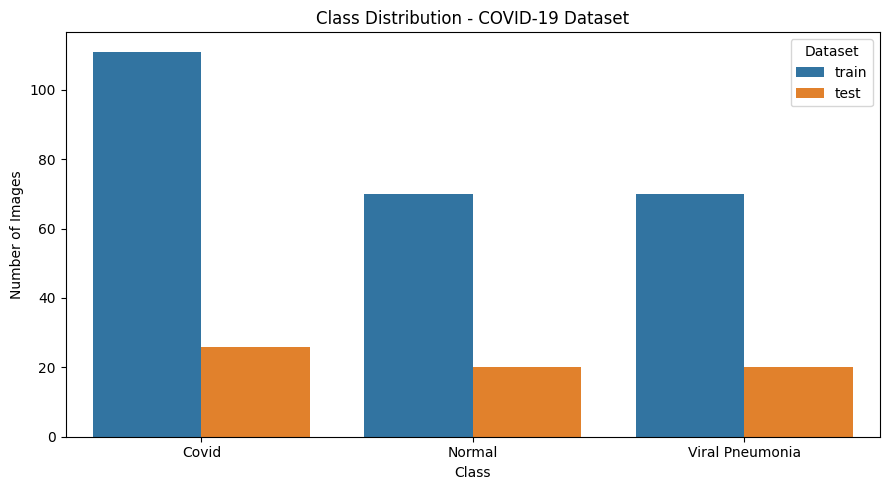

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_counts,
    x="Class",
    y="Image Count",
    hue="Dataset"
)

plt.title("Class Distribution - COVID-19 Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


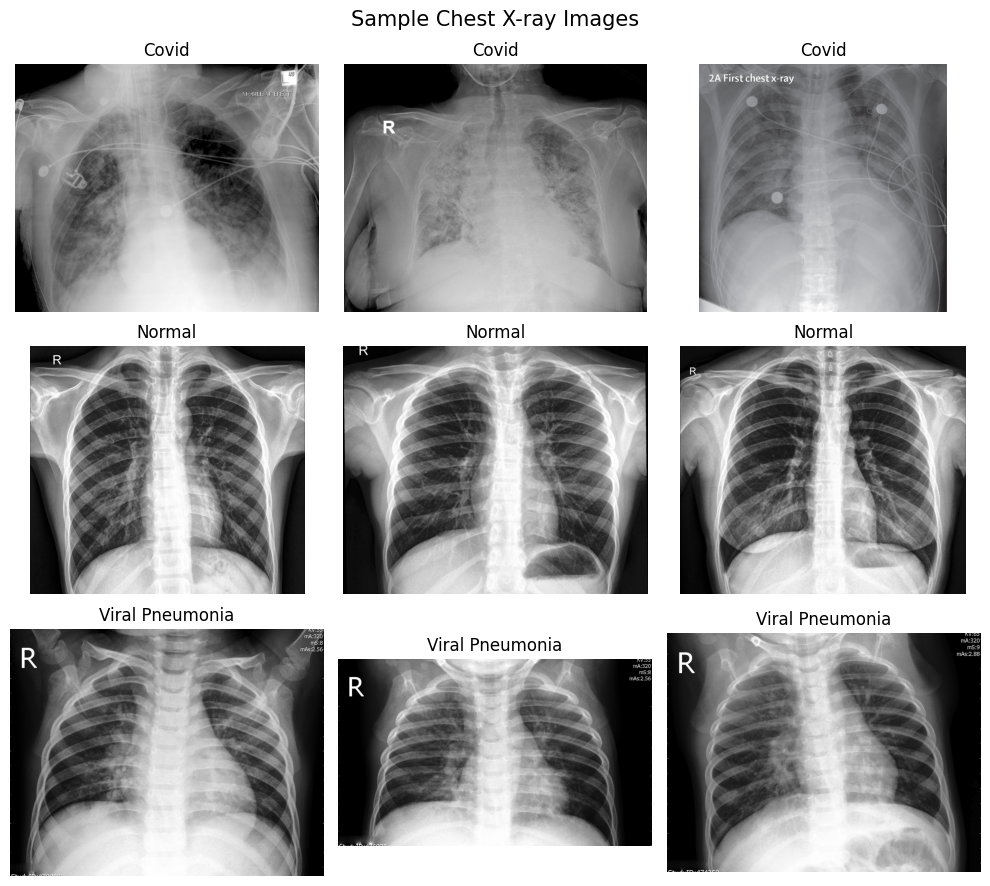

In [21]:
from PIL import Image
import os
import matplotlib.pyplot as plt

train_path = "/content/Covid19-dataset/train"
classes = sorted(os.listdir(train_path))

fig, axes = plt.subplots(
    len(classes), 3, figsize=(10, 9)
)

for i, class_name in enumerate(classes):
    class_path = os.path.join(train_path, class_name)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ][:3]

    for j, image_name in enumerate(images):
        img_path = os.path.join(class_path, image_name)
        img = Image.open(img_path).convert("RGB")

        axes[i, j].imshow(img)
        axes[i, j].set_title(class_name)
        axes[i, j].axis("off")

plt.suptitle("Sample Chest X-ray Images", fontsize=15)
plt.tight_layout()
plt.show()


Data Preprocessing

In [22]:

import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers

train_dir = "/content/Covid19-dataset/train"
test_dir = "/content/Covid19-dataset/test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

test_ds = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

print("Class Names:", class_names)


Found 251 files belonging to 3 classes.
Using 201 files for training.
Found 251 files belonging to 3 classes.
Using 50 files for validation.
Found 66 files belonging to 3 classes.
Class Names: ['Covid', 'Normal', 'Viral Pneumonia']


Normalize the images

In [23]:
from tensorflow.keras import layers

# Normalize pixel values from 0-255 to 0-1
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

# Verify normalization
for images, labels in train_ds.take(1):
    print("Image Shape:", images.shape)
    print("Minimum Pixel Value:", images.numpy().min())
    print("Maximum Pixel Value:", images.numpy().max())
    print("Labels Shape:", labels.shape)


Image Shape: (16, 224, 224, 3)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Labels Shape: (16,)


Build Basic CNN Model (Model 1)

In [24]:
import tensorflow as tf
from tensorflow.keras import layers, models

model1 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # First Convolutional Layer
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional Layer
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolutional Layer
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    layers.Flatten(),

    # Fully Connected Layer
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(3, activation='softmax')
])

model1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

Compile the Basic CNN model

In [25]:

model1.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Basic CNN Model Compiled Successfully!")


Basic CNN Model Compiled Successfully!


Train Basic CNN

In [26]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history1 = model1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)


Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 745ms/step - accuracy: 0.5075 - loss: 1.0726 - val_accuracy: 0.8000 - val_loss: 0.8343
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 342ms/step - accuracy: 0.7512 - loss: 0.7358 - val_accuracy: 0.8600 - val_loss: 0.5702
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 263ms/step - accuracy: 0.8507 - loss: 0.5104 - val_accuracy: 0.9200 - val_loss: 0.3852
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.8607 - loss: 0.3822 - val_accuracy: 0.9200 - val_loss: 0.3018
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 242ms/step - accuracy: 0.8756 - loss: 0.3194 - val_accuracy: 0.9400 - val_loss: 0.2253
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - accuracy: 0.8955 - loss: 0.2535 - val_accuracy: 0.9000 - val_loss: 0.2696
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step - accuracy: 0.9403 - loss: 0.1727 - val_accuracy: 0.9200 - val_loss: 0.2117
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 234ms/step - accuracy: 0.9502 - loss: 0.1341 - val_accuracy: 0

Training accuracy increased significantly, from 49.25% to 96.02%, indicating that the model learned patterns from the training images.

Validation accuracy reached 92% during training, which is encouraging.

Validation loss was lowest at epoch 5 (0.2298). It subsequently fluctuated while training loss continued to decrease.



There are early signs of overfitting, although the validation performance remains relatively strong.

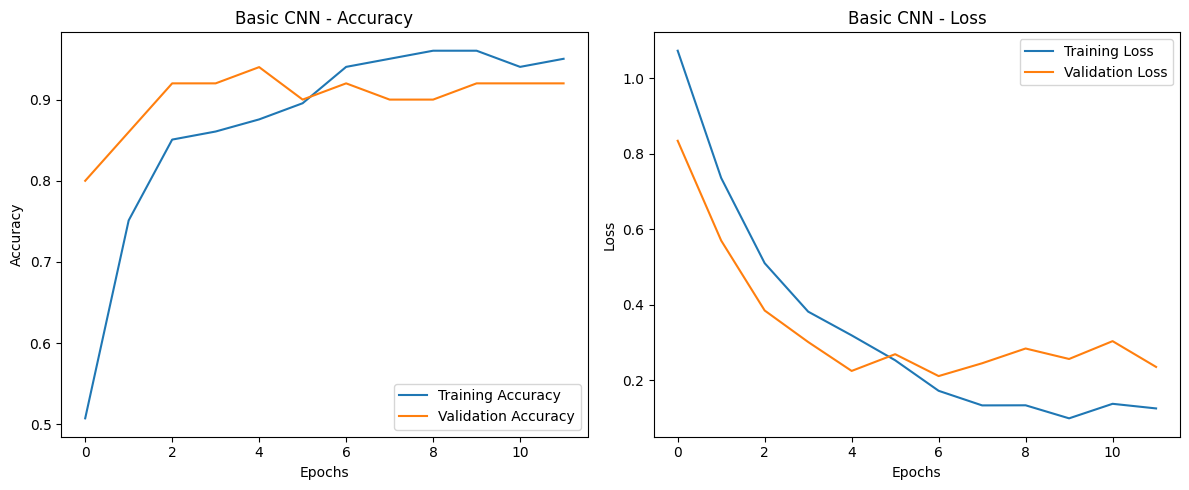

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history1.history['accuracy'], label='Training Accuracy')
plt.plot(history1.history['val_accuracy'], label='Validation Accuracy')
plt.title('Basic CNN - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history1.history['loss'], label='Training Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.title('Basic CNN - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [28]:
test_loss1, test_accuracy1 = model1.evaluate(
    test_ds,
    verbose=1
)

print(f"Basic CNN Test Accuracy: {test_accuracy1:.4f}")
print(f"Basic CNN Test Loss: {test_loss1:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.8939 - loss: 0.2963 
Basic CNN Test Accuracy: 0.8939
Basic CNN Test Loss: 0.2963


Accuracy graph: Training accuracy continues to increase, while validation accuracy fluctuates around 86–92%.

Loss graph: Training loss steadily decreases, but validation loss begins increasing after reaching its minimum.

Conclusion: The Basic CNN shows signs of overfitting. Its test accuracy of 78.79% is lower than its validation accuracy, suggesting that the model does not generalize as well to unseen test images.

This is one reason we'll compare it with more advanced CNN architectures.

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step


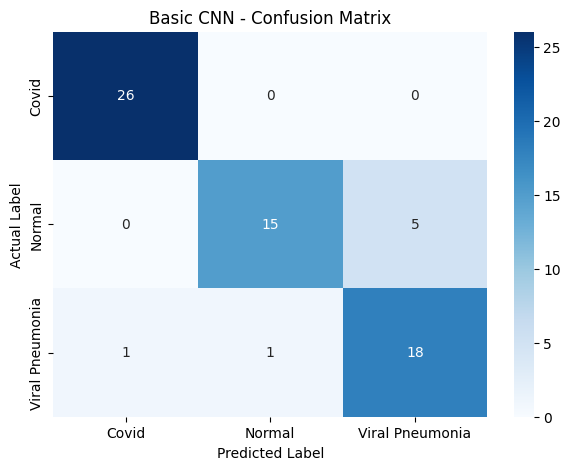

Basic CNN Classification Report:
                 precision    recall  f1-score   support

          Covid       0.96      1.00      0.98        26
         Normal       0.94      0.75      0.83        20
Viral Pneumonia       0.78      0.90      0.84        20

       accuracy                           0.89        66
      macro avg       0.89      0.88      0.88        66
   weighted avg       0.90      0.89      0.89        66

Weighted F1 Score: 0.8927


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score
)

# Get actual labels
y_true = np.concatenate([
    y.numpy() for x, y in test_ds
])

# Predict probabilities
y_prob1 = model1.predict(test_ds)

# Convert probabilities into class predictions
y_pred1 = np.argmax(y_prob1, axis=1)

# Confusion Matrix
cm1 = confusion_matrix(y_true, y_pred1)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm1,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Basic CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# Classification Report
print("Basic CNN Classification Report:")
print(classification_report(
    y_true,
    y_pred1,
    target_names=class_names,
    zero_division=0
))

# Weighted F1 Score
f1_1 = f1_score(
    y_true,
    y_pred1,
    average='weighted'
)

print("Weighted F1 Score:", round(f1_1, 4))


Basic CNN provides a useful baseline, but its generalization needs improvement. We will compare it with more advanced architectures.

Model 2 — Deep CNN

In [30]:
# Build Deep CNN architecture
from tensorflow.keras import layers, models

model2 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')
])

model2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 617,379 (2.36 MB)

 Trainable params: 616,419 (2.35 MB)

 Non-trainable params: 960 (3.75 KB)

In [31]:
model2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Deep CNN Model Compiled Successfully!")

Deep CNN Model Compiled Successfully!


In [32]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping2 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history2 = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping2]
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.6517 - loss: 0.7367 - val_accuracy: 0.4400 - val_loss: 1.0920
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 246ms/step - accuracy: 0.7711 - loss: 0.5808 - val_accuracy: 0.4400 - val_loss: 1.0804
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - accuracy: 0.8458 - loss: 0.4201 - val_accuracy: 0.4400 - val_loss: 1.0762
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - accuracy: 0.8607 - loss: 0.4318 - val_accuracy: 0.4400 - val_loss: 1.0778
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 213ms/step - accuracy: 0.9005 - loss: 0.3143 - val_accuracy: 0.4400 - val_loss: 1.0853
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 224ms/step - accuracy: 0.8955 - loss: 0.3009 - val_accuracy: 0.4400 - val_loss: 1.0981
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 223ms/step - accuracy: 0.8955 - loss: 0.2653 - val_accuracy: 0.4400 - val_loss: 1.1094
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 232ms/step - accuracy: 0.9453 - loss: 0.2027 - val_accuracy: 0.44

Training accuracy improved, suggesting the model learned patterns from the training images.

Validation accuracy remained stuck at 44% across all seven epochs.

Validation loss increased rather than decreased.

Early stopping correctly stopped training because validation loss was not improving.

In [33]:
import numpy as np
from collections import Counter

# Get actual validation labels
y_val_true = np.concatenate([
    y.numpy() for x, y in val_ds
])

# Get predicted probabilities
y_val_prob = model2.predict(val_ds)

# Convert probabilities to class labels
y_val_pred = np.argmax(y_val_prob, axis=1)

print("Actual Class Distribution:")
print(Counter(y_val_true))

print("\nPredicted Class Distribution:")
print(Counter(y_val_pred))

print("\nClass Names:", class_names)


4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 252ms/step
Actual Class Distribution:
Counter({np.int32(0): 22, np.int32(2): 17, np.int32(1): 11})

Predicted Class Distribution:
Counter({np.int64(0): 50})

Class Names: ['Covid', 'Normal', 'Viral Pneumonia']


Improve the Deep CNN architecture

In [34]:
from tensorflow.keras import layers, models

model2_improved = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3),
                  activation='relu',
                  padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3),
                  activation='relu',
                  padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3),
                  activation='relu',
                  padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3),
                  activation='relu',
                  padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')
])

model2_improved.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,699 (1.61 MB)

 Trainable params: 421,699 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

The revised architecture has approximately 31.7% fewer parameters than the original Deep CNN.

In [35]:
model2_improved.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Improved Deep CNN Compiled Successfully!")

Improved Deep CNN Compiled Successfully!


In [36]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping_improved = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

history2_improved = model2_improved.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_improved]
)


Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 495ms/step - accuracy: 0.3134 - loss: 1.0972 - val_accuracy: 0.4400 - val_loss: 1.1015
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step - accuracy: 0.3881 - loss: 1.0840 - val_accuracy: 0.4400 - val_loss: 1.0884
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - accuracy: 0.4328 - loss: 1.0807 - val_accuracy: 0.4400 - val_loss: 1.0820
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 222ms/step - accuracy: 0.4378 - loss: 1.0693 - val_accuracy: 0.4400 - val_loss: 1.0787
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - accuracy: 0.4527 - loss: 1.0665 - val_accuracy: 0.4400 - val_loss: 1.0717
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 221ms/step - accuracy: 0.4428 - loss: 1.0662 - val_accuracy: 0.4400 - val_loss: 1.0505
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 252ms/step - accuracy: 0.4527 - loss: 1.0459 - val_accuracy: 0.4600 - val_loss: 1.0379
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 225ms/step - accuracy: 0.5075 - loss: 1.0367 - val_accuracy: 0

Validation accuracy has improved from 44% to 60%. This suggests that the revised architecture is learning better than the previous model.

Training and validation losses are decreasing overall, which is a positive sign.

There is no strong evidence of overfitting at this stage.

However, the model is still performing below our Basic CNN, which achieved 92% validation accuracy and 78.79% test accuracy.

In [37]:
import numpy as np

print("Total Epochs Trained:",
      len(history2_improved.history['accuracy']))

print("Final Training Accuracy:",
      round(history2_improved.history['accuracy'][-1], 4))

print("Final Validation Accuracy:",
      round(history2_improved.history['val_accuracy'][-1], 4))

print("Best Validation Accuracy:",
      round(max(history2_improved.history['val_accuracy']), 4))

print("Lowest Validation Loss:",
      round(min(history2_improved.history['val_loss']), 4))

best_epoch = np.argmin(
    history2_improved.history['val_loss']
) + 1

print("Best Epoch (Validation Loss):", best_epoch)


Total Epochs Trained: 30
Final Training Accuracy: 0.7065
Final Validation Accuracy: 0.7
Best Validation Accuracy: 0.74
Lowest Validation Loss: 0.7003
Best Epoch (Validation Loss): 30


The improved architecture increased the best validation accuracy from 44% to 72%.

The lowest validation loss occurred at epoch 23.

Training accuracy remains relatively low, indicating that the model may be underfitting.

The Basic CNN still has better validation performance, reaching 92%.

Because early stopping restored the best weights, the current model should contain the weights from epoch 23, even though training continued to epoch 30.

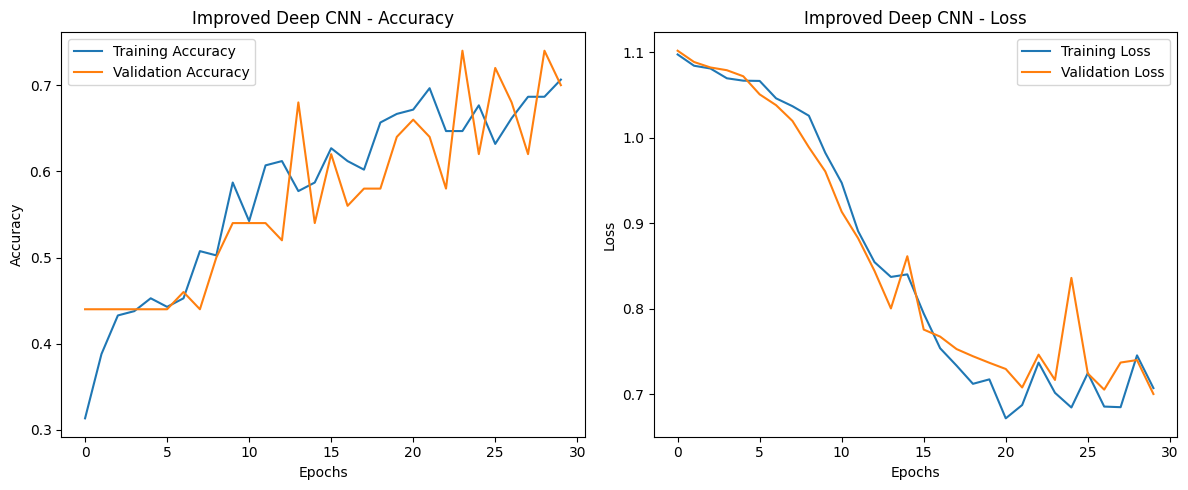

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - accuracy: 0.7000 - loss: 0.7003
Improved Deep CNN Validation Accuracy: 0.7000
Improved Deep CNN Validation Loss: 0.7003


In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history2_improved.history['accuracy'],
         label='Training Accuracy')
plt.plot(history2_improved.history['val_accuracy'],
         label='Validation Accuracy')
plt.title('Improved Deep CNN - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history2_improved.history['loss'],
         label='Training Loss')
plt.plot(history2_improved.history['val_loss'],
         label='Validation Loss')
plt.title('Improved Deep CNN - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate on validation dataset
val_loss2, val_accuracy2 = model2_improved.evaluate(
    val_ds,
    verbose=1
)

print(f"Improved Deep CNN Validation Accuracy: {val_accuracy2:.4f}")
print(f"Improved Deep CNN Validation Loss: {val_loss2:.4f}")


Training and validation accuracy increased gradually.
Both losses decreased substantially during training.
The training and validation curves remained relatively close, suggesting limited overfitting.
The model may be underfitting, as it has not learned enough to achieve strong classification performance.
The restored model achieves 68% validation accuracy because early stopping selects the weights with the lowest validation loss, not necessarily the highest validation accuracy.

Model 3 — VGG16 Transfer Learning

In [39]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

# Load pretrained VGG16
vgg_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
vgg_base.trainable = False

# Build VGG16 classification model
inputs = layers.Input(shape=(224, 224, 3))

# Existing datasets are normalized to 0-1
# Convert back to 0-255 for VGG16 preprocessing
x = layers.Rescaling(255.0)(inputs)

x = layers.Lambda(
    preprocess_input,
    output_shape=(224, 224, 3)
)(x)

x = vgg_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    3,
    activation='softmax'
)(x)

model3 = models.Model(inputs, outputs)

model3.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,739 (56.38 MB)

 Trainable params: 66,051 (258.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [40]:
model3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("VGG16 Model Compiled Successfully!")


VGG16 Model Compiled Successfully!


In [41]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping3 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history3 = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping3]
)


Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 566ms/step - accuracy: 0.3632 - loss: 6.2603 - val_accuracy: 0.3200 - val_loss: 3.9935
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 236ms/step - accuracy: 0.3831 - loss: 4.4799 - val_accuracy: 0.3600 - val_loss: 2.3957
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 242ms/step - accuracy: 0.4279 - loss: 4.3164 - val_accuracy: 0.5000 - val_loss: 1.7220
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step - accuracy: 0.4378 - loss: 3.9181 - val_accuracy: 0.6000 - val_loss: 1.4363
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 218ms/step - accuracy: 0.4975 - loss: 2.8285 - val_accuracy: 0.6600 - val_loss: 1.1961
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 239ms/step - accuracy: 0.5672 - loss: 2.6394 - val_accuracy: 0.6800 - val_loss: 1.0812
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 224ms/step - accuracy: 0.6318 - loss: 1.7598 - val_accuracy: 0.7400 - val_loss: 0.9141
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step - accuracy: 0.6418 - loss: 2.2433 - val_accuracy: 

Training accuracy improved from 39.30% to 79.10%.

Validation accuracy improved from 48% to 84%.

Validation loss decreased from 3.8709 to 0.5009.

There is no clear evidence of significant overfitting at this stage.

Validation accuracy is higher than training accuracy, which can happen because dropout is active during training but disabled during validation.

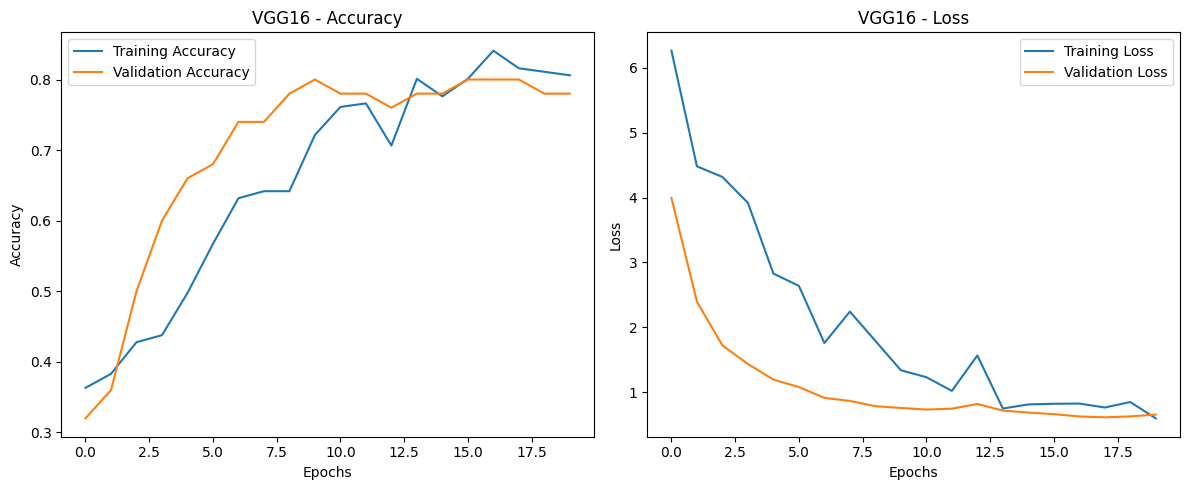

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.8000 - loss: 0.6153
VGG16 Validation Accuracy: 0.8000
VGG16 Validation Loss: 0.6153


In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history3.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history3.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('VGG16 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history3.history['loss'],
    label='Training Loss'
)

plt.plot(
    history3.history['val_loss'],
    label='Validation Loss'
)

plt.title('VGG16 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate VGG16 on validation data
val_loss3, val_accuracy3 = model3.evaluate(
    val_ds,
    verbose=1
)

print(f"VGG16 Validation Accuracy: {val_accuracy3:.4f}")
print(f"VGG16 Validation Loss: {val_loss3:.4f}")

Training accuracy increased steadily, reaching approximately 79%.

Validation accuracy reached 84%, indicating that the model learned useful features.

Both training and validation losses decreased throughout training.

There is no substantial gap between training and validation performance.

The model may benefit from fine-tuning, but improvement is not guaranteed.

In [43]:
# Unfreeze VGG16 base
vgg_base.trainable = True

# Freeze all layers except block5
for layer in vgg_base.layers:
    if layer.name.startswith("block5"):
        layer.trainable = True
    else:
        layer.trainable = False

# Check trainable layers
for layer in vgg_base.layers:
    if layer.trainable:
        print(layer.name)

print("\nTrainable Parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in model3.trainable_weights))


block5_conv1
block5_conv2
block5_conv3
block5_pool

Trainable Parameters: 7145475


In [44]:
model3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("VGG16 Fine-Tuning Model Compiled Successfully!")


VGG16 Fine-Tuning Model Compiled Successfully!


In [45]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping_ft = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

checkpoint_ft = ModelCheckpoint(
    'vgg16_finetuned_best.weights.h5',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=True
)

history3_ft = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        early_stopping_ft,
        checkpoint_ft
    ]
)


Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 562ms/step - accuracy: 0.8358 - loss: 0.5933 - val_accuracy: 0.8200 - val_loss: 0.5532
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 269ms/step - accuracy: 0.8657 - loss: 0.4719 - val_accuracy: 0.9200 - val_loss: 0.2611
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step - accuracy: 0.9204 - loss: 0.2920 - val_accuracy: 0.9200 - val_loss: 0.2869
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - accuracy: 0.9204 - loss: 0.2624 - val_accuracy: 0.8800 - val_loss: 0.3022
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - accuracy: 0.9652 - loss: 0.0894 - val_accuracy: 0.8600 - val_loss: 0.3285
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step - accuracy: 0.9552 - loss: 0.0911 - val_accuracy: 0.8600 - val_loss: 0.3199


Fine-tuning improved validation accuracy by 6 percentage points.

Validation loss decreased, indicating better predictions on the validation dataset.

Training accuracy reached nearly 99%, while validation accuracy remained at 90%.

The gap between training and validation accuracy suggests possible overfitting, particularly because our dataset is small.

The best validation loss occurred at epoch 11, so early stopping should have restored those weights.

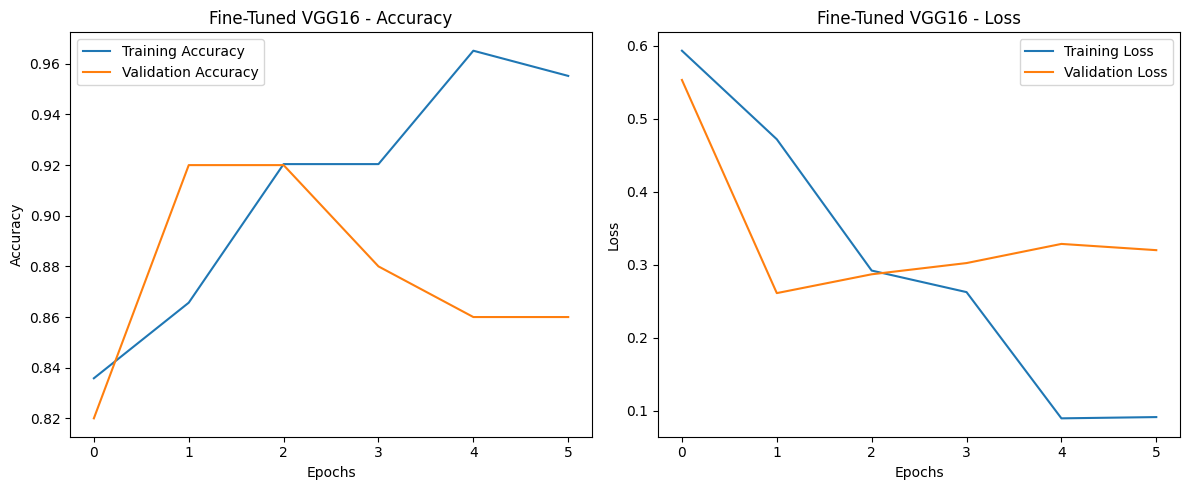

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - accuracy: 0.9200 - loss: 0.2611
Fine-Tuned VGG16 Validation Accuracy: 0.9200
Fine-Tuned VGG16 Validation Loss: 0.2611


In [46]:
import matplotlib.pyplot as plt

# Plot accuracy and loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history3_ft.history['accuracy'],
         label='Training Accuracy')
plt.plot(history3_ft.history['val_accuracy'],
         label='Validation Accuracy')
plt.title('Fine-Tuned VGG16 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history3_ft.history['loss'],
         label='Training Loss')
plt.plot(history3_ft.history['val_loss'],
         label='Validation Loss')
plt.title('Fine-Tuned VGG16 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate restored best model
val_loss3_ft, val_accuracy3_ft = model3.evaluate(
    val_ds,
    verbose=1
)

print(f"Fine-Tuned VGG16 Validation Accuracy: {val_accuracy3_ft:.4f}")
print(f"Fine-Tuned VGG16 Validation Loss: {val_loss3_ft:.4f}")


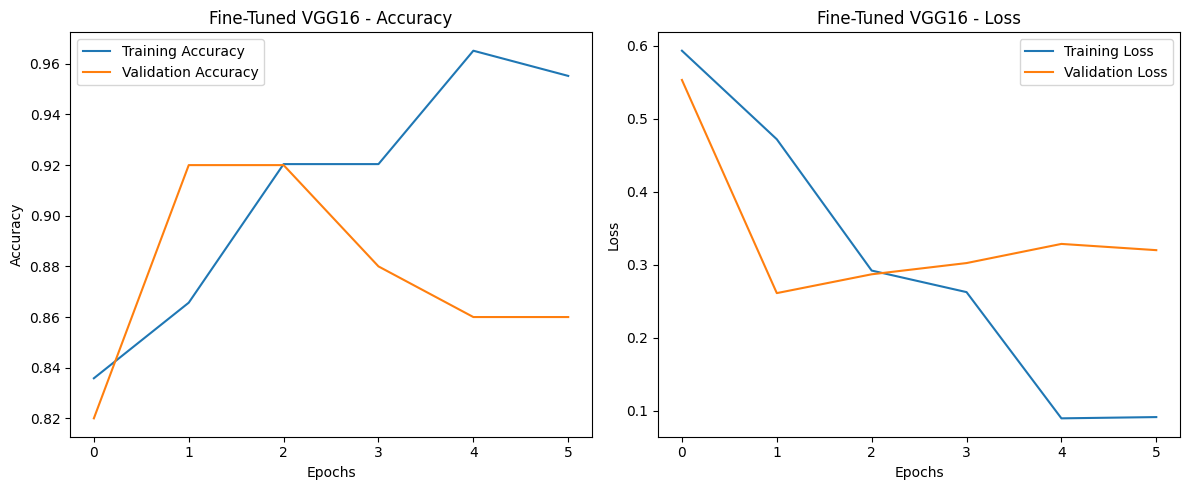

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history3_ft.history['accuracy'],
         label='Training Accuracy')
plt.plot(history3_ft.history['val_accuracy'],
         label='Validation Accuracy')
plt.title('Fine-Tuned VGG16 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history3_ft.history['loss'],
         label='Training Loss')
plt.plot(history3_ft.history['val_loss'],
         label='Validation Loss')
plt.title('Fine-Tuned VGG16 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [48]:
val_loss3_ft, val_accuracy3_ft = model3.evaluate(
    val_ds,
    verbose=1
)

print("Fine-Tuned VGG16 Validation Accuracy:",
      round(val_accuracy3_ft, 4))

print("Fine-Tuned VGG16 Validation Loss:",
      round(val_loss3_ft, 4))


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 254ms/step - accuracy: 0.9200 - loss: 0.2611
Fine-Tuned VGG16 Validation Accuracy: 0.92
Fine-Tuned VGG16 Validation Loss: 0.2611


In [49]:
model3.save_weights("vgg16_finetuned.weights.h5")

print("VGG16 fine-tuned weights saved successfully!")


VGG16 fine-tuned weights saved successfully!


Model 4 — ResNet50 Transfer Learning

In [50]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# Load pretrained ResNet50
resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

# Build classification model
inputs = layers.Input(shape=(224, 224, 3))

# Existing dataset images are normalized to 0-1
x = layers.Rescaling(255.0)(inputs)

# ResNet50-specific preprocessing
x = layers.Lambda(
    preprocess_input,
    output_shape=(224, 224, 3)
)(x)

# Feature extraction
x = resnet_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

# Classification layers
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    3,
    activation='softmax'
)(x)

model4 = models.Model(inputs, outputs)

model4.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [51]:
model4.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ResNet50 Model Compiled Successfully!")


ResNet50 Model Compiled Successfully!


In [52]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping4 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history4 = model4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping4]
)


Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.3831 - loss: 1.6560 - val_accuracy: 0.6000 - val_loss: 0.9734
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.6219 - loss: 1.0038 - val_accuracy: 0.8600 - val_loss: 0.4865
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.7612 - loss: 0.5530 - val_accuracy: 0.8400 - val_loss: 0.3964
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 229ms/step - accuracy: 0.8209 - loss: 0.4056 - val_accuracy: 0.8600 - val_loss: 0.3616
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.8706 - loss: 0.3699 - val_accuracy: 0.8800 - val_loss: 0.3381
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 240ms/step - accuracy: 0.8756 - loss: 0.3078 - val_accuracy: 0.8600 - val_loss: 0.3253
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 232ms/step - accuracy: 0.9104 - loss: 0.2847 - val_accuracy: 0.9000 - val_loss: 0.2927
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 251ms/step - accuracy: 0.9104 - loss: 0.2471 - val_accuracy: 0.88

Training accuracy increased significantly, indicating that the model learned useful image features.

Validation accuracy reached 90% at several epochs.

Validation loss decreased substantially, reaching 0.2278 at epoch 18.

Training accuracy is higher than validation accuracy, suggesting some overfitting.
ResNet50 is a promising candidate for the final model.

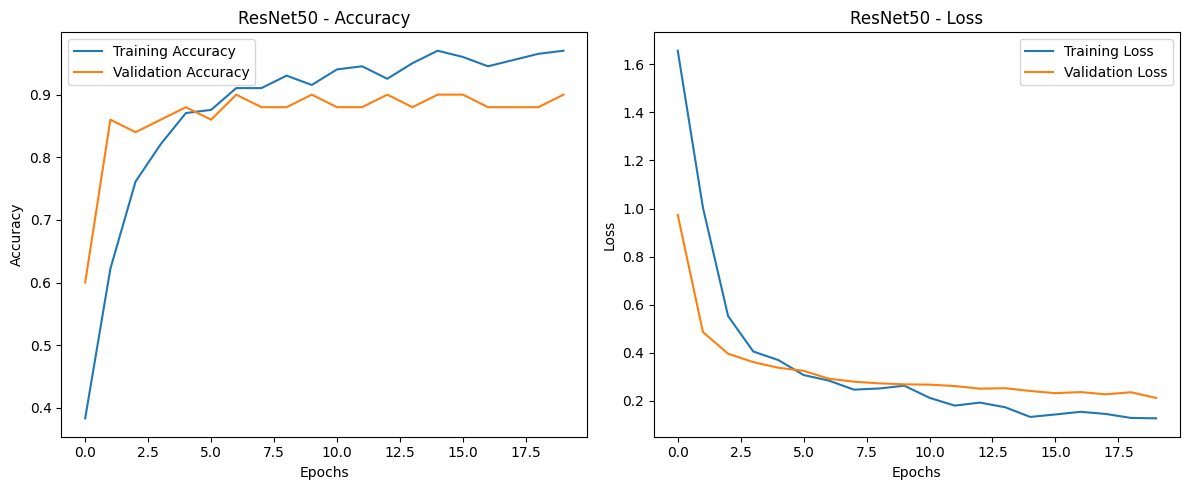

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history4.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history4.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('ResNet50 - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history4.history['loss'],
    label='Training Loss'
)

plt.plot(
    history4.history['val_loss'],
    label='Validation Loss'
)

plt.title('ResNet50 - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [54]:
val_loss4, val_accuracy4 = model4.evaluate(
    val_ds,
    verbose=1
)

print("ResNet50 Validation Accuracy:",
      round(val_accuracy4, 4))

print("ResNet50 Validation Loss:",
      round(val_loss4, 4))

print("Best Validation Accuracy:",
      round(max(history4.history['val_accuracy']), 4))

print("Lowest Validation Loss:",
      round(min(history4.history['val_loss']), 4))


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 181ms/step - accuracy: 0.9000 - loss: 0.2129
ResNet50 Validation Accuracy: 0.9
ResNet50 Validation Loss: 0.2129
Best Validation Accuracy: 0.9
Lowest Validation Loss: 0.2129


Training accuracy increased from approximately 38% to 97%.

Validation accuracy improved to 90% and remained relatively stable during later epochs.

Training and validation loss decreased significantly.

A gap developed between training and validation accuracy, indicating some overfitting.

ResNet50 achieved a lower validation loss than fine-tuned VGG16, although VGG16 achieved slightly higher validation accuracy.

Data augmentation layer

In [55]:
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.03, 0.03)
], name="data_augmentation")

print("Data Augmentation Created Successfully!")


Data Augmentation Created Successfully!


In [56]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# Load pretrained ResNet50
resnet_base_aug = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base_aug.trainable = False

# Input layer
inputs_aug = layers.Input(shape=(224, 224, 3))

# Apply data augmentation
x = data_augmentation(inputs_aug)

# Convert normalized images back to 0-255
x = layers.Rescaling(255.0)(x)

# ResNet50 preprocessing
x = layers.Lambda(
    preprocess_input,
    output_shape=(224, 224, 3)
)(x)

# Feature extraction
x = resnet_base_aug(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)

# Output layer
outputs_aug = layers.Dense(
    3,
    activation='softmax'
)(x)

# Create model
model5 = models.Model(inputs_aug, outputs_aug)

# Display summary
model5.summary()


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [57]:
model5.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ResNet50 + Data Augmentation Compiled Successfully!")

ResNet50 + Data Augmentation Compiled Successfully!


In [58]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping5 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history5 = model5.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping5]
)


Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 363ms/step - accuracy: 0.4627 - loss: 1.2647 - val_accuracy: 0.7200 - val_loss: 0.7602
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.6169 - loss: 0.8751 - val_accuracy: 0.7800 - val_loss: 0.5870
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step - accuracy: 0.7313 - loss: 0.6683 - val_accuracy: 0.8400 - val_loss: 0.4818
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.7910 - loss: 0.5199 - val_accuracy: 0.8000 - val_loss: 0.4959
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 251ms/step - accuracy: 0.8010 - loss: 0.4776 - val_accuracy: 0.8800 - val_loss: 0.4390
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 246ms/step - accuracy: 0.9104 - loss: 0.3088 - val_accuracy: 0.8200 - val_loss: 0.4317
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.8706 - loss: 0.3813 - val_accuracy: 0.8400 - val_loss: 0.3857
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 232ms/step - accuracy: 0.8955 - loss: 0.2843 - val_accuracy: 0

Training accuracy increased from 46.27% to 92.54%, indicating that the model learned meaningful image features.

Validation accuracy improved from 72% to 86%, reaching a maximum of 88%.

Validation loss decreased from 0.7602 to 0.3266.

Training accuracy is higher than validation accuracy, indicating some overfitting.

The lowest validation loss occurred at epoch 20, suggesting that further training might help, although improvement is not guaranteed.

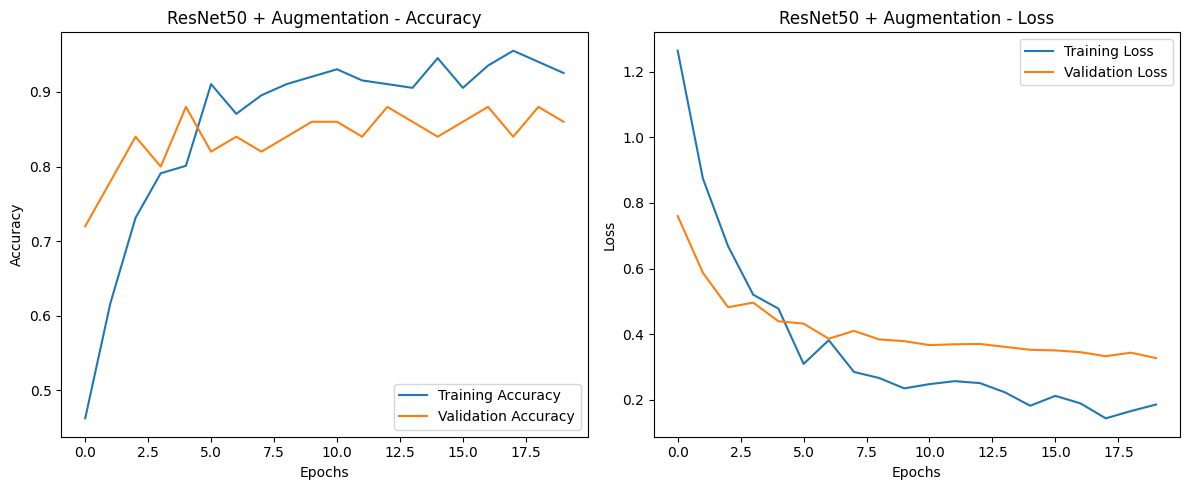

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)

plt.plot(
    history5.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history5.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('ResNet50 + Augmentation - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)

plt.plot(
    history5.history['loss'],
    label='Training Loss'
)

plt.plot(
    history5.history['val_loss'],
    label='Validation Loss'
)

plt.title('ResNet50 + Augmentation - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [60]:
val_loss5, val_accuracy5 = model5.evaluate(
    val_ds,
    verbose=1
)

print("ResNet50 + Augmentation Validation Accuracy:",
      round(val_accuracy5, 4))

print("ResNet50 + Augmentation Validation Loss:",
      round(val_loss5, 4))


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 201ms/step - accuracy: 0.8600 - loss: 0.3266
ResNet50 + Augmentation Validation Accuracy: 0.86
ResNet50 + Augmentation Validation Loss: 0.3266


The original ResNet50 performed better on the validation dataset, achieving 90% accuracy compared with 86%.

The augmented model's training accuracy reached approximately 92.5%, while validation accuracy was 86%.

Training loss continued decreasing, but validation loss improved more slowly, indicating some overfitting.

Data augmentation did not improve performance in this particular experiment.

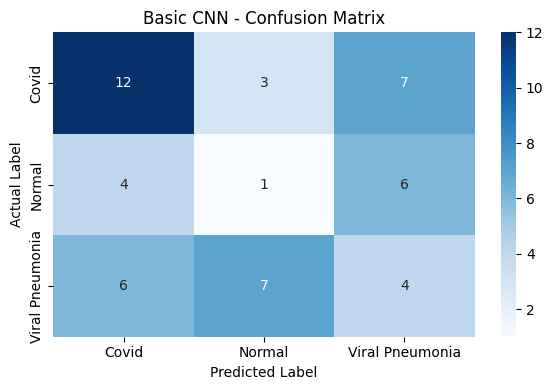


Basic CNN - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.55      0.55      0.55        22
         Normal       0.09      0.09      0.09        11
Viral Pneumonia       0.24      0.24      0.24        17

       accuracy                           0.34        50
      macro avg       0.29      0.29      0.29        50
   weighted avg       0.34      0.34      0.34        50



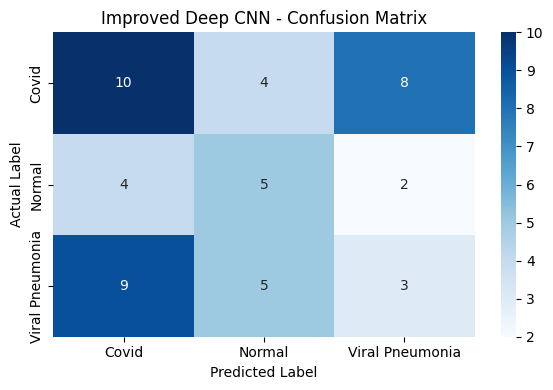


Improved Deep CNN - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.43      0.45      0.44        22
         Normal       0.36      0.45      0.40        11
Viral Pneumonia       0.23      0.18      0.20        17

       accuracy                           0.36        50
      macro avg       0.34      0.36      0.35        50
   weighted avg       0.35      0.36      0.35        50



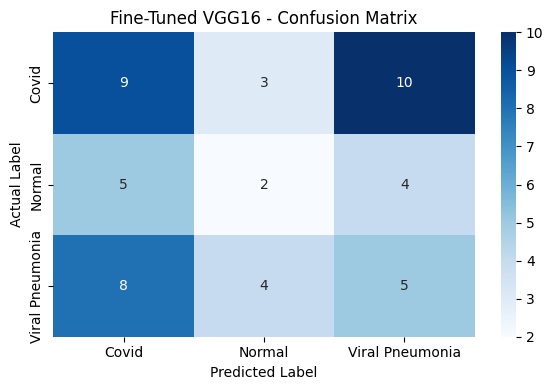


Fine-Tuned VGG16 - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.41      0.41      0.41        22
         Normal       0.22      0.18      0.20        11
Viral Pneumonia       0.26      0.29      0.28        17

       accuracy                           0.32        50
      macro avg       0.30      0.30      0.30        50
   weighted avg       0.32      0.32      0.32        50



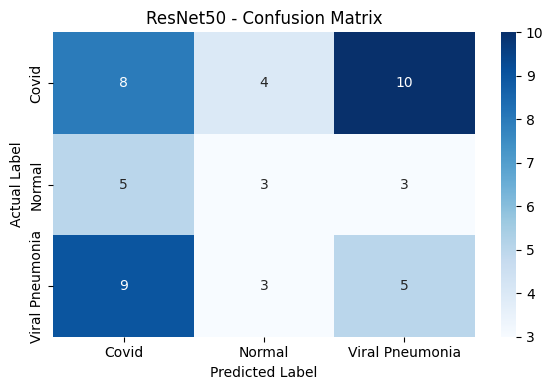


ResNet50 - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.36      0.36      0.36        22
         Normal       0.30      0.27      0.29        11
Viral Pneumonia       0.28      0.29      0.29        17

       accuracy                           0.32        50
      macro avg       0.31      0.31      0.31        50
   weighted avg       0.32      0.32      0.32        50



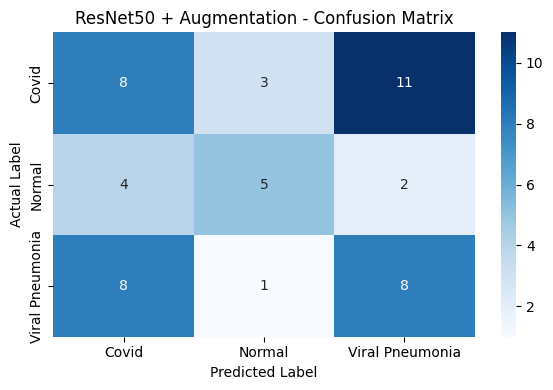


ResNet50 + Augmentation - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.40      0.36      0.38        22
         Normal       0.56      0.45      0.50        11
Viral Pneumonia       0.38      0.47      0.42        17

       accuracy                           0.42        50
      macro avg       0.45      0.43      0.43        50
   weighted avg       0.43      0.42      0.42        50



In [61]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

# Actual validation labels
y_val_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

# Models to compare
models_dict = {
    "Basic CNN": model1,
    "Improved Deep CNN": model2_improved,
    "Fine-Tuned VGG16": model3,
    "ResNet50": model4,
    "ResNet50 + Augmentation": model5
}

# Store evaluation results
model_results = []

for model_name, model in models_dict.items():

    # Predicted probabilities
    y_val_prob = model.predict(val_ds, verbose=0)

    # Predicted class labels
    y_val_pred = np.argmax(y_val_prob, axis=1)

    # Confusion matrix
    cm = confusion_matrix(
        y_val_true,
        y_val_pred,
        labels=range(len(class_names))
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.tight_layout()
    plt.show()

    # Classification report
    print(f"\n{model_name} - Classification Report:")

    print(classification_report(
        y_val_true,
        y_val_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    # Store results
    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val_true, y_val_pred),
        "Weighted F1": f1_score(
            y_val_true,
            y_val_pred,
            average='weighted',
            zero_division=0
        )
    })


In [62]:
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers

# Create validation dataset without shuffling
val_ds_fixed = image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

# Normalize images to 0-1
normalization_layer = layers.Rescaling(1./255)

val_ds_fixed = val_ds_fixed.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Validation dataset created successfully!")


Found 251 files belonging to 3 classes.
Using 50 files for validation.
Validation dataset created successfully!


In [63]:
import numpy as np
import tensorflow as tf

# Collect images and corresponding labels together
val_images = []
val_labels = []

for images, labels in val_ds:
    val_images.append(images.numpy())
    val_labels.append(labels.numpy())

val_images = np.concatenate(val_images, axis=0)
y_val_true = np.concatenate(val_labels, axis=0)

print("Validation Images Shape:", val_images.shape)
print("Validation Labels Shape:", y_val_true.shape)
print("Class Names:", class_names)


Validation Images Shape: (50, 224, 224, 3)
Validation Labels Shape: (50,)
Class Names: ['Covid', 'Normal', 'Viral Pneumonia']


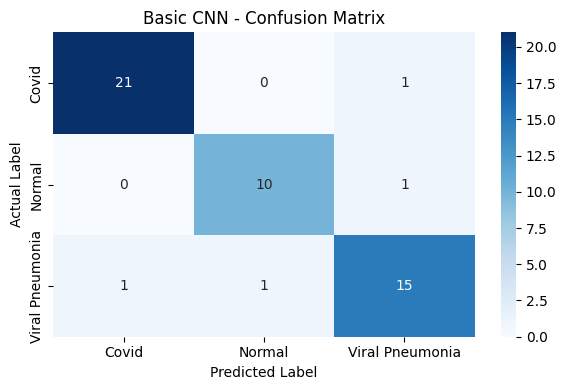


Basic CNN - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.95      0.95      0.95        22
         Normal       0.91      0.91      0.91        11
Viral Pneumonia       0.88      0.88      0.88        17

       accuracy                           0.92        50
      macro avg       0.92      0.92      0.92        50
   weighted avg       0.92      0.92      0.92        50



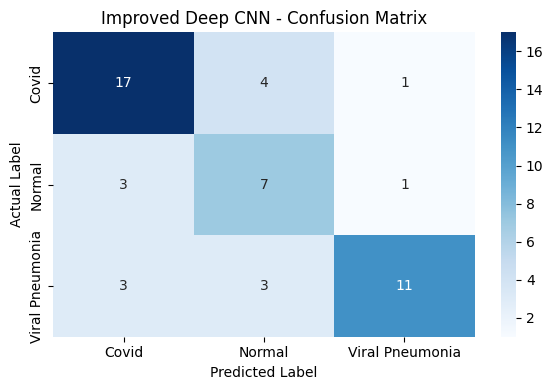


Improved Deep CNN - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.74      0.77      0.76        22
         Normal       0.50      0.64      0.56        11
Viral Pneumonia       0.85      0.65      0.73        17

       accuracy                           0.70        50
      macro avg       0.70      0.69      0.68        50
   weighted avg       0.72      0.70      0.70        50



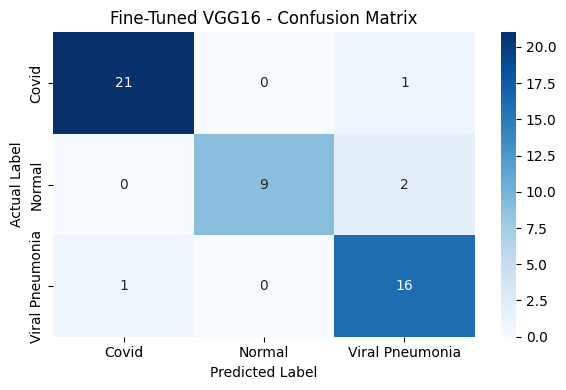


Fine-Tuned VGG16 - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.95      0.95      0.95        22
         Normal       1.00      0.82      0.90        11
Viral Pneumonia       0.84      0.94      0.89        17

       accuracy                           0.92        50
      macro avg       0.93      0.90      0.91        50
   weighted avg       0.93      0.92      0.92        50



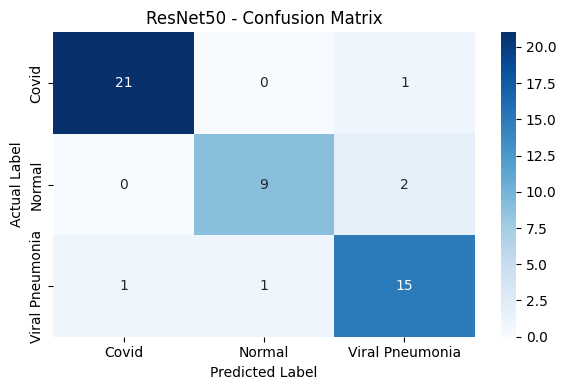


ResNet50 - Classification Report:
                 precision    recall  f1-score   support

          Covid       0.95      0.95      0.95        22
         Normal       0.90      0.82      0.86        11
Viral Pneumonia       0.83      0.88      0.86        17

       accuracy                           0.90        50
      macro avg       0.90      0.89      0.89        50
   weighted avg       0.90      0.90      0.90        50



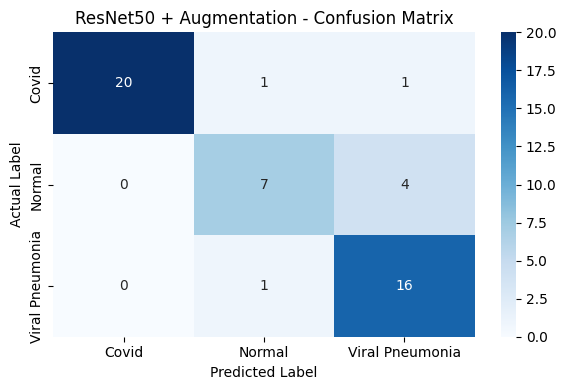


ResNet50 + Augmentation - Classification Report:
                 precision    recall  f1-score   support

          Covid       1.00      0.91      0.95        22
         Normal       0.78      0.64      0.70        11
Viral Pneumonia       0.76      0.94      0.84        17

       accuracy                           0.86        50
      macro avg       0.85      0.83      0.83        50
   weighted avg       0.87      0.86      0.86        50


Model Comparison:


,Model,Accuracy,Weighted F1
0,Basic CNN,0.92,0.920000
1,Improved Deep CNN,0.70,0.704978
2,Fine-Tuned VGG16,0.92,0.920222
3,ResNet50,0.90,0.900000
4,ResNet50 + Augmentation,0.86,0.859363


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

# Models to evaluate
models_dict = {
    "Basic CNN": model1,
    "Improved Deep CNN": model2_improved,
    "Fine-Tuned VGG16": model3,
    "ResNet50": model4,
    "ResNet50 + Augmentation": model5
}

model_results = []

for model_name, model in models_dict.items():

    # Predict using the SAME images collected with labels
    y_val_prob = model.predict(
        val_images,
        verbose=0
    )

    y_val_pred = np.argmax(y_val_prob, axis=1)

    # Calculate accuracy
    accuracy = accuracy_score(
        y_val_true,
        y_val_pred
    )

    # Calculate weighted F1 score
    weighted_f1 = f1_score(
        y_val_true,
        y_val_pred,
        average='weighted',
        zero_division=0
    )

    # Confusion Matrix
    cm = confusion_matrix(
        y_val_true,
        y_val_pred,
        labels=range(len(class_names))
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.tight_layout()
    plt.show()

    # Classification Report
    print(f"\n{model_name} - Classification Report:")

    print(classification_report(
        y_val_true,
        y_val_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    # Store results
    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Weighted F1": weighted_f1
    })

# Model comparison dataframe
df_model_results = pd.DataFrame(model_results)

print("\nModel Comparison:")
display(df_model_results)


Basic CNN and Fine-Tuned VGG16 achieved the highest validation accuracy of 92%, correctly classifying 46 out of 50 images each.

Fine-Tuned VGG16 achieved a marginally higher weighted F1-score than Basic CNN.

ResNet50 also performed well, achieving 90% accuracy.

ResNet50 + Augmentation achieved 86%, suggesting augmentation did not improve validation performance in this experiment.

Improved Deep CNN performed the weakest, with 70% accuracy.

In [65]:

from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
import pandas as pd
import numpy as np

# Convert actual labels to binary format
y_val_bin = label_binarize(
    y_val_true,
    classes=[0, 1, 2]
)

auc_results = []

for model_name, model in models_dict.items():

    # Predict probabilities
    y_val_prob = model.predict(
        val_images,
        verbose=0
    )

    # Calculate AUC for each class
    auc_scores = []

    for i in range(len(class_names)):
        auc = roc_auc_score(
            y_val_bin[:, i],
            y_val_prob[:, i]
        )
        auc_scores.append(auc)

    auc_results.append({
        "Model": model_name,
        "Covid AUC": auc_scores[0],
        "Normal AUC": auc_scores[1],
        "Viral Pneumonia AUC": auc_scores[2],
        "Macro AUC": np.mean(auc_scores)
    })

df_auc = pd.DataFrame(auc_results)

display(df_auc.round(4))


,Model,Covid AUC,Normal AUC,Viral Pneumonia AUC,Macro AUC
0,Basic CNN,0.9951,0.9837,0.9804,0.9864
1,Improved Deep CNN,0.9188,0.8438,0.8485,0.8704
2,Fine-Tuned VGG16,0.9854,1.0000,0.9679,0.9844
3,ResNet50,0.9919,0.9860,0.9733,0.9837
4,ResNet50 + Augmentation,0.9708,0.9697,0.9501,0.9635


Basic CNN achieved the highest macro AUC (0.9864), indicating excellent class discrimination on the validation dataset.



Fine-Tuned VGG16 achieved a Normal-class AUC of 1.0000, although this is based on a small validation sample.



ResNet50 also demonstrated strong discrimination, with a macro AUC of 0.9837.



Improved Deep CNN had the lowest macro AUC at 0.8704.

In [66]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Collect test images and labels together
test_images = []
test_labels = []

for images, labels in test_ds:
    test_images.append(images.numpy())
    test_labels.append(labels.numpy())

test_images = np.concatenate(test_images, axis=0)
y_test_true = np.concatenate(test_labels, axis=0)

print("Test Images Shape:", test_images.shape)
print("Test Labels Shape:", y_test_true.shape)
print("Test Class Distribution:",
      np.bincount(y_test_true, minlength=3))


Test Images Shape: (66, 224, 224, 3)
Test Labels Shape: (66,)
Test Class Distribution: [26 20 20]


In [67]:
print("Minimum Pixel Value:", test_images.min())
print("Maximum Pixel Value:", test_images.max())

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


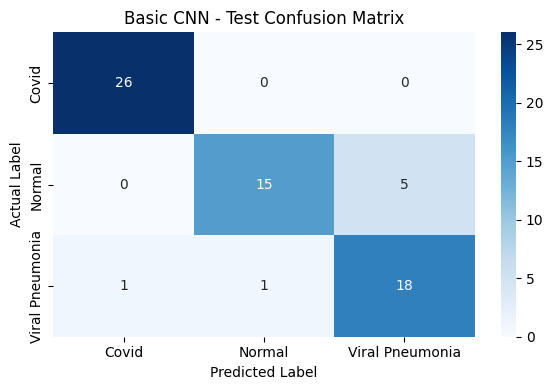


Basic CNN - Test Classification Report:
                 precision    recall  f1-score   support

          Covid       0.96      1.00      0.98        26
         Normal       0.94      0.75      0.83        20
Viral Pneumonia       0.78      0.90      0.84        20

       accuracy                           0.89        66
      macro avg       0.89      0.88      0.88        66
   weighted avg       0.90      0.89      0.89        66



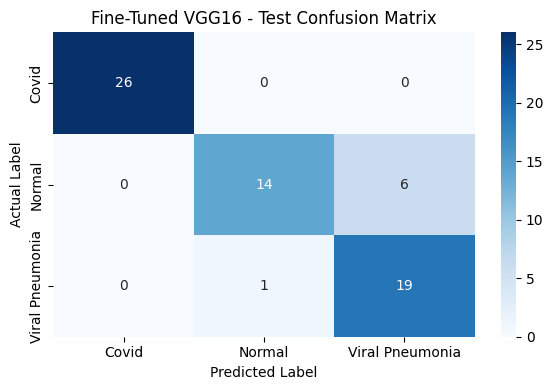


Fine-Tuned VGG16 - Test Classification Report:
                 precision    recall  f1-score   support

          Covid       1.00      1.00      1.00        26
         Normal       0.93      0.70      0.80        20
Viral Pneumonia       0.76      0.95      0.84        20

       accuracy                           0.89        66
      macro avg       0.90      0.88      0.88        66
   weighted avg       0.91      0.89      0.89        66


Final Test Model Comparison:


,Model,Test Accuracy,Test Precision,Test Recall,Test F1
0,Basic CNN,0.8939,0.9006,0.8939,0.8927
1,Fine-Tuned VGG16,0.8939,0.9071,0.8939,0.8923


In [68]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Select the two leading models
final_models = {
    "Basic CNN": model1,
    "Fine-Tuned VGG16": model3
}

test_results = []

for model_name, model in final_models.items():

    # Predict probabilities
    y_test_prob = model.predict(
        test_images,
        verbose=0
    )

    # Convert probabilities to predicted classes
    y_test_pred = np.argmax(y_test_prob, axis=1)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test_true, y_test_pred)

    precision = precision_score(
        y_test_true, y_test_pred,
        average='weighted', zero_division=0
    )

    recall = recall_score(
        y_test_true, y_test_pred,
        average='weighted', zero_division=0
    )

    f1 = f1_score(
        y_test_true, y_test_pred,
        average='weighted', zero_division=0
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_test_true,
        y_test_pred,
        labels=range(len(class_names))
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{model_name} - Test Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    print(f"\n{model_name} - Test Classification Report:")

    print(classification_report(
        y_test_true,
        y_test_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    test_results.append({
        "Model": model_name,
        "Test Accuracy": accuracy,
        "Test Precision": precision,
        "Test Recall": recall,
        "Test F1": f1
    })

df_test_results = pd.DataFrame(test_results)

print("\nFinal Test Model Comparison:")
display(df_test_results.round(4))


Both models achieved 89.39% test accuracy, correctly classifying 59 out of 66 images.

Both models correctly identified all 26 COVID images in the test dataset.

Basic CNN performed slightly better at identifying Normal images.

Fine-Tuned VGG16 performed slightly better at identifying Viral Pneumonia images.

The weighted F1-score difference is negligible.

In [69]:
# Select final model
final_model = model1

# Save model in Keras format
final_model.save("covid_cnn_model.keras")

print("Final CNN Model Saved Successfully!")


Final CNN Model Saved Successfully!


In [70]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class Names Saved Successfully!")
print(class_names)


Class Names Saved Successfully!
['Covid', 'Normal', 'Viral Pneumonia']


In [71]:
from google.colab import files

files.download("covid_cnn_model.keras")
files.download("class_names.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
final_model = model1
final_model.save("covid_cnn_model.keras")

In [73]:
import tensorflow as tf
import numpy as np
import json

# Load saved model
loaded_model = tf.keras.models.load_model(
    "covid_cnn_model.keras"
)

# Load class names
with open("class_names.json", "r") as f:
    loaded_class_names = json.load(f)

# Predict using original model
original_predictions = final_model.predict(
    test_images[:5],
    verbose=0
)

# Predict using loaded model
loaded_predictions = loaded_model.predict(
    test_images[:5],
    verbose=0
)

# Compare predictions
print("Predictions Match:",
      np.allclose(original_predictions,
                  loaded_predictions,
                  atol=1e-6))

print("Loaded Class Names:", loaded_class_names)
print("Loaded Model Input Shape:",
      loaded_model.input_shape)

print("Model Loaded Successfully!")


Predictions Match: True
Loaded Class Names: ['Covid', 'Normal', 'Viral Pneumonia']
Loaded Model Input Shape: (None, 224, 224, 3)
Model Loaded Successfully!
